# Twenty-First-Century Warming in the Hector Simple Climate Model: Active Subspaces of Matilda's Six Uncertain Parameters

__Joseph K. Brown__, __Leeya Pressburger__, __Abigail Snyder__, __Kalyn Dorheim__, __Steven J. Smith__, __Claudia Tebaldi__, __Ben Bond-Lamberty__

Joint Global Change Research Institute, Pacific Northwest National Laboratory, College Park, MD, United States of America

Notebook: Claude (Anthropic) for P. Constantine, 2026

Paper: J. K. Brown et al., "Matilda v1.0: An R package for probabilistic climate projections using a reduced complexity climate model", *PLOS Climate* 3(5): e0000295 (2024), [doi:10.1371/journal.pclm.0000295](https://doi.org/10.1371/journal.pclm.0000295).

In [1]:
%matplotlib inline
import time

import numpy as np
import matplotlib.pyplot as plt
import active_subspaces as ac
import hector_driver as hd   # prior definitions and the z -> x map (numpy only); running Hector needs R

SEED = 2024                  # the only seed in this notebook (bootstrap)
t_start = time.perf_counter()
sym = [p[1] for p in hd.PARAMS]
lab = [r'$\alpha$', r'$\beta$', 'ECS', r'$K_{eff}$', r'NPP$_0$', r'$Q_{10}$']

### Summary

Brown et al. [1] present Matilda, an R package that draws Hector's six uncertain parameters from literature priors, runs the model as a perturbed parameter ensemble, weights the members against observed temperature and reports probabilistic warming; they report no sensitivity or active-subspace results. We ran Hector 3.1.1 under SSP2-4.5 at 1000 Monte Carlo draws from Matilda's priors, with finite-difference gradients at 400 of them, and find that 2081–2100 warming is essentially a function of one direction in the scaled inputs ($\lambda_1/\lambda_2 = 36.8$ at the shipped finite-difference step, and roughly 28–47 under a ±30 % change of the step-sensitive NPP$_0$ gradient component; $\lambda_1$ holds 95.8 % of the trace), dominated by climate sensitivity with smaller carbon-cycle and aerosol contributions. A quadratic in that one variable predicts warming with leave-one-out $R^2 = 0.983$; CO$_2$ in 2100 has a weaker one-dimensional structure built from the carbon-cycle parameters, and the paper's weighted probabilities are compared at the end: we find 96.9 % for the paper's 1.7–3.8 °C range against its 92 %, and show that a likely (unconfirmed) cause is a misalignment of weights and runs in the paper's analysis scripts, which leaves their result close to the unweighted one.

### Active subspaces in brief

For a function $f(\mathbf z)$ of $m$ inputs with density $\rho$, here independent standard normal inputs $\mathbf z\sim N(\mathbf 0, \mathbf I_6)$, the active subspace is spanned by the leading eigenvectors of
$$\mathbf C = \int \nabla f(\mathbf z)\,\nabla f(\mathbf z)^T\rho(\mathbf z)\,d\mathbf z = \mathbf W\Lambda\mathbf W^T,\qquad \lambda_1\ge\dots\ge\lambda_m\ge 0 .$$
If the first $n$ eigenvalues are much larger than the rest, $f$ varies mostly along the active variables $\mathbf y = \mathbf W_1^T\mathbf z$ and changes little along $\mathbf W_2^T\mathbf z$; a plot of $f$ against $\mathbf y$ (a sufficient summary plot) then shows almost all of its variation. We estimate $\mathbf C$ by the Monte Carlo average $\hat{\mathbf C} = \frac1M\sum_i\nabla f(\mathbf z_i)\nabla f(\mathbf z_i)^T$ and its variability by a bootstrap. See P. G. Constantine, *Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*, SIAM (2015), [doi:10.1137/1.9781611973860](https://doi.org/10.1137/1.9781611973860).

### The model

**Hector.** Hector is an open-source, object-oriented simple carbon-cycle climate model written in C++, with a global spatial scale and an annual time step; it converts emissions to atmospheric concentrations, computes radiative forcing from them, and derives global temperature change from the total forcing [1, pp. 2–3]. Matilda, the paper's R package, perturbs Hector's parameters to build perturbed parameter ensembles, weights the members against observations and computes probabilistic projections [1, Sec. 2, Fig. 1]. The paper does not print Hector's equations; they are in the Hector model papers [2, 3]. We run Hector 3.1.1, the version the paper cites [1, ref. 22], under SSP2-4.5, the scenario of the paper's worked example [1, Sec. 2, pp. 3–4], with Hector's bundled `hector_ssp245.ini` (emissions-driven CO$_2$).

**Inputs.** Matilda's `generate_params()` draws six parameters independently from the priors of the paper's Table 1 (p. 5), "mean ± standard deviation", normal or lognormal [1, Eq. (1), p. 5]:

| input | Hector name | description | units | prior (Table 1, p. 5) | source cited there |
|---|---|---|---|---|---|
| $\alpha$ | `AERO_SCALE` | aerosol forcing scaling factor | – | Normal, 1.0 ± 0.23 | Smith et al. (2020) |
| $\beta$ | `BETA` | CO$_2$ fertilization factor | – | Normal, 0.55 ± 0.10 | Jones et al. (2013) |
| ECS | `ECS` | equilibrium climate sensitivity | °C | Lognormal, 3.0 ± 0.65 | Sherwood et al. (2020) |
| $K_{eff}$ | `DIFFUSIVITY` | ocean heat diffusivity | cm$^2$ s$^{-1}$ | Normal, 1.16 ± 0.118 | Vega-Westhoff et al. (2019) |
| NPP$_0$ | `NPP_FLUX0` | pre-industrial net primary productivity | Pg C yr$^{-1}$ | Normal, 56.2 ± 14.3 | Ito (2011) |
| $Q_{10}$ | `Q10_RH` | temperature sensitivity of heterotrophic respiration | – | Lognormal, 2.2 ± 1.0 | Davidson and Janssens (2006) |

For the two lognormal priors the paper says only that "(μ, σ) is substituted by log(μ, σ)" (p. 5). Matilda's code (`lognorm()` in `R/iterate_model.R`, tag v1.0.0) treats 3.0 ± 0.65 and 2.2 ± 1.0 as the arithmetic mean and standard deviation of the parameter, $x = e^{\mu_\ell + s z}$ with $\mu_\ell = \ln\!\big(m^2/\sqrt{s_x^2+m^2}\big)$ and $s = \sqrt{\ln(1+s_x^2/m^2)}$; we follow the code. The means are Hector 3.1.1's defaults (Matilda reads them from the core).

**Scaled inputs.** Each input is written as a function of one standard normal variable: $x = \mu + \sigma z$ for the normal priors and $x = e^{\mu_\ell + s z}$ for the lognormal ones. The active subspace is computed in $\mathbf z\in\mathbb R^6$, so every input is scaled through its own prior to $N(0,1)$, and gradients are $\partial f/\partial z_j$.

**Quantity of interest.** The case study's metric is long-term warming, the 2081–2100 mean of global mean surface temperature relative to the pre-industrial reference 1850–1900 [1, Sec. 3, p. 17]:
$$f(\mathbf z) = \frac{1}{20}\sum_{t=2081}^{2100}\mathrm{GMST}_t(\mathbf z) - \frac{1}{51}\sum_{t=1850}^{1900}\mathrm{GMST}_t(\mathbf z)\quad(^\circ\mathrm C),$$
with each run's own 1850–1900 mean subtracted (this data set's reading of "relative to 1850–1900"; see the comparison section for how the paper's code does it). A second output, the CO$_2$ concentration in 2100 (ppmv), is analysed briefly; it responds to the carbon-cycle parameters.

**Weights.** Matilda's `score_bayesian` weights each run by its fit to observed GMST [1, Eqs. (4)–(6), p. 9]: $\mathrm{RMSE}_i = \big(\frac1N\sum_t ((Y(t)-m_i(t))/\sigma_Y)^2\big)^{1/2}$, $L_i = e^{-\frac12(\mathrm{RMSE}_i/\sigma_{\mathrm{RMSE}})^2}$, $\omega_i = L_i/\sum_j L_j$. In Matilda v1.0.0 the observations are HadCRUT5-based annual anomalies for 1950–2023 (`criterion_gmst_obs()`), and the defaults are $\sigma_Y$ = sd of the observed series and $\sigma_{\mathrm{RMSE}}$ = sd of the RMSE values (`score_bayesian`), which the case study keeps [1, p. 17]. The weights are stored, for the comparison with the paper; the active subspace uses the prior density.

Below, the priors as implemented (`hector_driver.PARAMS`; log-mean and log-sd of the lognormal ones; values at $z = \pm 3$):

In [2]:
print(f"{'input':12s} {'symbol':6s} {'units':7s} {'prior':10s} {'mean':>6s} {'sd':>6s} "
      f"{'log-mean':>8s} {'log-sd':>7s} {'median':>7s} {'z = -3':>8s} {'z = +3':>8s}")
lo, med, hi = hd.z_to_x(np.array([-3.0, 0.0, 3.0])[:, None] * np.ones(6))
for j, (name, s, u, mean, sd, kind) in enumerate(hd.PARAMS):
    if kind == 'lognormal':
        mu, sl = hd.lognormal_params(mean, sd)
        extra = f'{mu:8.4f} {sl:7.4f}'
    else:
        extra = f"{'':8s} {'':7s}"
    print(f'{name:12s} {s:6s} {u:7s} {kind:10s} {mean:6.3g} {sd:6.3g} {extra} {med[j]:7.4g} '
          f'{lo[j]:8.4g} {hi[j]:8.4g}')

input        symbol units   prior        mean     sd log-mean  log-sd  median   z = -3   z = +3
AERO_SCALE   alpha  1       normal          1   0.23                        1     0.31     1.69
BETA         beta   1       normal       0.55    0.1                     0.55     0.25     0.85
ECS          ECS    degC    lognormal       3   0.65   1.0757  0.2142   2.932    1.542    5.575
DIFFUSIVITY  Keff   cm2/s   normal       1.16  0.118                     1.16    0.806    1.514
NPP_FLUX0    NPP0   PgC/yr  normal       56.2   14.3                     56.2     13.3     99.1
Q10_RH       Q10    1       lognormal     2.2      1   0.6945  0.4334   2.003   0.5458     7.35


### Load data

`generate_data.py` drew 1000 Monte Carlo samples $\mathbf z\sim N(\mathbf 0,\mathbf I_6)$ (numpy `default_rng`, seed 20240502), mapped them to the six parameters, and ran Hector 3.1.1 through Matilda's `set_params` under SSP2-4.5. It stored the warming, the CO$_2$ concentration in 2100, each run's 1850–1900 mean GMST, the raw GMST of 1950–2023, and Matilda's RMSE and weight. At the first 400 samples it stored the gradients of the warming and of CO$_2$ in 2100 with respect to $\mathbf z$ by central differences with step $h = 0.25$ (12 extra runs per sample). The step is large on purpose: Hector's outputs are not smooth at small scales (scans with spacing 0.025 in $z$ show a sawtooth with jumps of up to about $10^{-2}$ °C in warming and 5–8 ppmv in CO$_2$ per step, along NPP$_0$, $Q_{10}$ and ECS and, at some samples, along every input), so small steps return noise and the gradients are smoothed slopes whose values depend on the step; the step-size and roughness checks are in `DATA.md`, Accuracy.

In [3]:
IN = np.loadtxt('inputs.csv', delimiter=',')            # (1000, 12): z_1..z_6, then the physical inputs
OUT = np.loadtxt('outputs.csv', delimiter=',')          # (1000, 5): warming degC, co2_2100 ppmv, gmst_1850_1900 degC, rmse, weight
GM = np.loadtxt('gmst_1950_2023.csv', delimiter=',')    # (1000, 74): raw Hector gmst 1950-2023, degC
GR = np.loadtxt('gradients.csv', delimiter=',')         # (400, 12): d warming/dz_j (degC), d co2/dz_j (ppmv)
Z, X = IN[:, :6], IN[:, 6:]
warm, co2, gref, rmse, wts = OUT.T
ok = np.isfinite(OUT[:, :4]).all(1)          # rule: drop runs where Hector failed (NaN outputs)
gok = np.isfinite(GR).all(1)                 # same rule for gradients (a failed stencil run)
assert ok[:len(GR)].all()
Zg, Gw, Gc = Z[:len(GR)][gok], GR[gok, :6], GR[gok, 6:]
Mg = len(Gw)
Zk, Xk, warmk, co2k, grefk, rmsek, wtsk = Z[ok], X[ok], warm[ok], co2[ok], gref[ok], rmse[ok], wts[ok]
for n, a in [('Z', Z), ('X', X), ('warming', warm), ('co2_2100', co2), ('gmst_1850_1900', gref), ('rmse', rmse), ('weight', wts),
             ('gmst', GM), ('grad warming', Gw), ('grad co2', Gc)]:
    print(f'{n:13s} {a.shape}')

Z             (1000, 6)
X             (1000, 6)
warming       (1000,)
co2_2100      (1000,)
gmst_1850_1900 (1000,)
rmse          (1000,)
weight        (1000,)
gmst          (1000, 74)
grad warming  (399, 6)
grad co2      (399, 6)


We check that the stored physical inputs are the stated functions of the scaled inputs, that the scaled inputs look standard normal, and which samples are outside physical meaning or failed. We also check the gradient coordinates by comparing the least-squares slope of each output on $\mathbf z$ with the mean gradient (they agree when the gradients are taken in the stated coordinates).

In [4]:
print(f'max |X - x(Z)| / |X| = {np.max(np.abs(X - hd.z_to_x(Z)) / np.abs(X)):.1e}')
kurt = np.mean((Z - Z.mean(0))**4, 0) / Z.var(0)**2
print('z: means', np.array2string(Z.mean(0), precision=3), '; sds', np.array2string(Z.std(0, ddof=1), precision=3),
      '; kurtosis', np.array2string(kurt, precision=2))
print('physical inputs, sample mean (sd):',
      ', '.join(f'{s} {m:.3g} ({d:.3g})' for s, m, d in zip(sym, X.mean(0), X.std(0, ddof=1))))
print(f'failed runs (NaN outputs): {np.sum(~ok)}, rows', np.where(~ok)[0], '; their inputs:',
      ', '.join(f'{s} {v:.4g} (z {z:+.2f})' for s, v, z in zip(sym, X[~ok][0], Z[~ok][0])) if (~ok).any() else '')
print(f'gradient rows with a NaN: {np.sum(~gok)}, rows', np.where(~gok)[0], '; NPP0 there',
      ', '.join(f'{v:.2f} (z {z:+.2f})' for v, z in zip(X[:len(GR)][~gok, 4], Z[:len(GR)][~gok, 4])))
print(f'the analysis below uses the {ok.sum()} finite runs and the {Mg} finite gradient rows')
print(f'samples with a non-positive alpha, beta, Keff or NPP0: {np.sum((X[:, [0, 1, 3, 4]] <= 0).any(1))}; '
      f'with Q10 < 1 (respiration falling with temperature): {np.sum(X[:, 5] < 1)}; minimum Q10 {X[:, 5].min():.3f}')
q = np.percentile(warmk, [5, 50, 95])
print(f'warming 2081-2100 (degC): mean {warmk.mean():.3f}, sd {warmk.std(ddof=1):.3f}, '
      f'5-50-95 % {q[0]:.2f} {q[1]:.2f} {q[2]:.2f}, range [{warmk.min():.2f}, {warmk.max():.2f}]')
q = np.percentile(co2k, [5, 50, 95])
print(f'CO2 in 2100 (ppmv): mean {co2k.mean():.1f}, sd {co2k.std(ddof=1):.1f}, 5-50-95 % {q[0]:.0f} {q[1]:.0f} {q[2]:.0f}')
print(f'weights: sum {wtsk.sum():.6f}, max {wtsk.max():.4f}, effective sample size 1/sum(w^2) = {1 / np.sum(wtsk**2):.0f}')
# gradient coordinates: least-squares slope on z vs the mean gradient (first Mg rows)
for name, f, G in [('warming', warm, Gw), ('co2_2100', co2, Gc)]:
    A = np.column_stack([np.ones(Mg), Zg])
    b = np.linalg.lstsq(A, f[:len(GR)][gok], rcond=None)[0][1:]
    g = G.mean(0)
    print(f'{name:9s}: OLS slope on z vs mean gradient: cosine {b @ g / np.linalg.norm(b) / np.linalg.norm(g):.4f}, '
          f'norms {np.linalg.norm(b):.4f} and {np.linalg.norm(g):.4f}')

max |X - x(Z)| / |X| = 2.2e-16
z: means [-0.013 -0.021  0.003  0.024  0.004  0.002] ; sds [1.007 0.992 1.017 1.003 1.044 1.006] ; kurtosis [2.81 2.91 2.94 3.04 3.13 3.1 ]
physical inputs, sample mean (sd): alpha 0.997 (0.231), beta 0.548 (0.0992), ECS 3 (0.661), Keff 1.16 (0.118), NPP0 56.3 (14.9), Q10 2.2 (1.01)
failed runs (NaN outputs): 1, rows [568] ; their inputs: alpha 0.9943 (z -0.02), beta 0.302 (z -2.48), ECS 1.891 (z -2.05), Keff 1.071 (z -0.76), NPP0 2.284 (z -3.77), Q10 1.825 (z -0.21)
gradient rows with a NaN: 1, rows [336] ; NPP0 there 11.71 (z -3.11)
the analysis below uses the 999 finite runs and the 399 finite gradient rows
samples with a non-positive alpha, beta, Keff or NPP0: 0; with Q10 < 1 (respiration falling with temperature): 51; minimum Q10 0.453
warming 2081-2100 (degC): mean 2.454, sd 0.543, 5-50-95 % 1.67 2.40 3.40, range [1.18, 4.79]
CO2 in 2100 (ppmv): mean 549.9, sd 51.7, 5-50-95 % 471 547 638
weights: sum 1.000000, max 0.0024, effective sample size 1/sum

The physical inputs are exactly the stated maps of $\mathbf z$, and the scaled inputs have sample means within 0.03 of 0, standard deviations 0.99–1.04 and kurtosis 2.81–3.13 (normal: 3); the physical sample means and standard deviations match Table 1. One run failed (row 568, NPP$_0$ = 2.284 Pg C yr$^{-1}$ at $z = -3.77$), and one gradient row (336, NPP$_0$ = 11.71 at $z = -3.11$) has a NaN because a stencil point at lower NPP$_0$ failed; both are dropped by the rule "non-finite output", leaving 999 runs and 399 gradient rows. No sample has a non-positive $\alpha$, $\beta$, $K_{eff}$ or NPP$_0$; 51 have $Q_{10} < 1$, which Hector accepts, and they are kept. Warming has mean 2.454 °C and standard deviation 0.543 °C (5–95 % range 1.67–3.40 °C); the weights have an effective sample size of 608. The least-squares slope and the mean gradient point the same way (cosine 0.9996 for warming, 0.9990 for CO$_2$), so the gradients are in the stated coordinates.

### Estimate the subspace

We have gradients, so we use the gradient estimator (`estimator="as"`) on the 400 samples with gradients, with the input space `ac.Gaussian(0, I)` in the scaled coordinates $\mathbf z$ and a 500-replicate bootstrap (`SEED` = 2024). The finite-difference gradients depend on the step, by a few per cent for warming and, for CO$_2$, by about 10 % in the median and 25–50 % in some components (`DATA.md`, Accuracy); we check the result against two estimators that use only the 999 function values (QPHD and OLS).

In [5]:
space = ac.Gaussian(np.zeros(6), np.ones(6), names=sym)
sub = ac.active_subspace(space=space, X=Zg, grads=Gw, estimator='as', nboot=500, rng=SEED)
subc = ac.active_subspace(space=space, X=Zg, grads=Gc, estimator='as', nboot=500, rng=SEED)
for name, s in [('warming', sub), ('co2_2100', subc)]:
    lam = s.eigenvalues
    lo_, hi_ = np.percentile(s.bootstrap_eigenvalues, [2.5, 97.5], axis=0)
    print(f'{name}: eigenvalues', np.array2string(lam, precision=4))
    print('   95 % bootstrap intervals', ', '.join(f'[{a:.3g}, {b:.3g}]' for a, b in zip(lo_, hi_)))
    print('   ratios lambda_k/lambda_k+1', np.array2string(lam[:-1] / lam[1:], precision=2),
          f'; lambda1/trace = {lam[0] / lam.sum():.4f}, (lambda1+lambda2)/trace = {lam[:2].sum() / lam.sum():.4f}')
    print('   gap rule (evg) picks n =', ac.dimension_criterion(s, rule='evg')[2])

warming: eigenvalues [3.0270e-01 8.2158e-03 2.8514e-03 1.4565e-03 4.7694e-04 2.0740e-04]
   95 % bootstrap intervals [0.29, 0.314], [0.00507, 0.014], [0.00217, 0.00358], [0.000578, 0.00228], [0.000207, 0.000657], [3.08e-05, 0.000235]
   ratios lambda_k/lambda_k+1 [36.84  2.88  1.96  3.05  2.3 ] ; lambda1/trace = 0.9582, (lambda1+lambda2)/trace = 0.9842
   gap rule (evg) picks n = 1
co2_2100: eigenvalues [2863.2321  334.2022   79.5031   27.3366   18.317     3.4996]
   95 % bootstrap intervals [2.73e+03, 3.01e+03], [237, 495], [33.4, 150], [23, 31.3], [3.85, 23.7], [1.79, 4.83]
   ratios lambda_k/lambda_k+1 [8.57 4.2  2.91 1.49 5.23] ; lambda1/trace = 0.8608, (lambda1+lambda2)/trace = 0.9613
   gap rule (evg) picks n = 1


### Results: warming 2081–2100

**Eigenvalues and subspace errors** (warming; 95 % bootstrap bands):

bootstrap mean subspace distance, k = 1..5: [0.013 0.17  0.229 0.32  0.391]


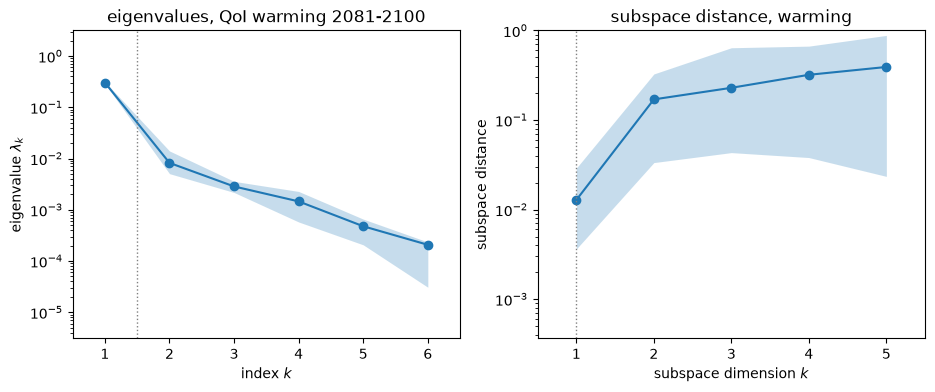

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ac.plotting.plot_eigenvalues(sub, ax=axes[0])
axes[0].set_title('eigenvalues, QoI warming 2081-2100')
ac.plotting.plot_subspace_errors(sub, ax=axes[1])
axes[1].set_title('subspace distance, warming')
plt.close(fig)
print('bootstrap mean subspace distance, k = 1..5:',
      np.array2string(sub.bootstrap_distances.mean(axis=0), precision=3))
fig

The first eigenvalue, 0.303, is 36.8 times the second (0.00822), and holds 95.8 % of the trace; the next ratios are 2.88, 1.96, 3.05 and 2.30, so after the first gap the spectrum decays without a clear second gap. The bootstrap intervals of $\lambda_1$ ([0.29, 0.314]) and $\lambda_2$ ([0.00507, 0.014]) are far apart, the mean bootstrap distance of the one-dimensional subspace is 0.013, and for $k = 2$ it is 0.17. The gap rule picks $n = 1$. We choose $n = 1$: the gap, the small subspace error and the surrogate below (LOO $R^2$ 0.983 in one variable) agree. A second direction is real but small, and its subspace distance (0.17) says it is poorly determined. The value of the ratio depends on the finite-difference step (it moves to about 28–47 in the check below), so read 36.8 as "about 30–45"; the gap, not its exact size, is what matters.

**Eigenvectors.** The paper has no eigenvector figure; the sign rule is that ECS has a positive component in $\mathbf w_1$ and NPP$_0$ a positive one in $\mathbf w_2$ (`ac.orient`). Right: the share of the trace from each input, $E[(\partial f/\partial z_i)^2]/\mathrm{tr}\,\hat{\mathbf C}$.

w1: alpha -0.171, beta -0.252, ECS +0.862, Keff -0.064, NPP0 -0.288, Q10 +0.277
w2: alpha -0.216, beta -0.159, ECS -0.034, Keff +0.079, NPP0 +0.738, Q10 +0.613
w3: alpha +0.172, beta +0.185, ECS +0.476, Keff -0.034, NPP0 +0.603, Q10 -0.587
E[(df/dz_i)^2]/trace: alpha 0.0312, beta 0.0652, ECS 0.7145, Keff 0.0054, NPP0 0.0970, Q10 0.0869
mean gradient: alpha -0.0914, beta -0.1348, ECS +0.4654, Keff -0.0322, NPP0 -0.1580, Q10 +0.1459 ; |w1 . mean gradient direction| = 1.0000


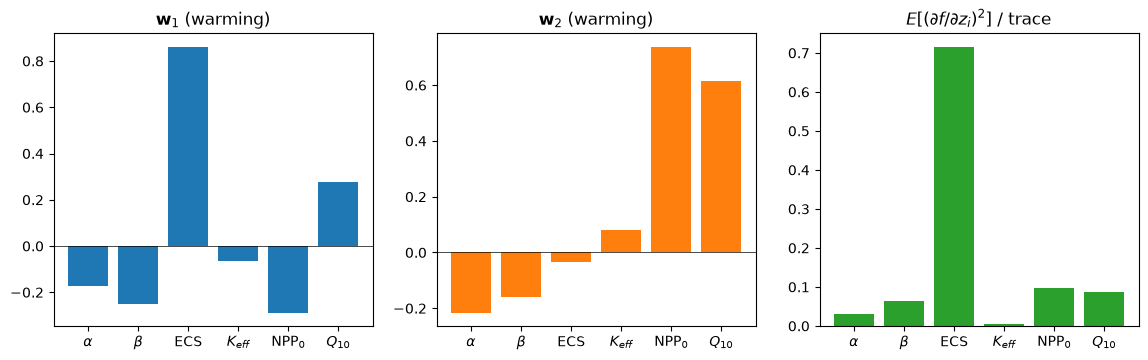

In [7]:
sub = ac.orient(sub, by='reference', reference=np.eye(6)[:, [2, 4]], columns=2)   # ECS > 0 in w1, NPP0 > 0 in w2
W = sub.W
lam = sub.eigenvalues
act = (W[:, :1]**2 * lam[:1]).sum(1)
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for k in range(2):
    axes[k].bar(range(6), W[:, k], color=f'C{k}')
    axes[k].axhline(0, color='k', lw=.5)
    axes[k].set_xticks(range(6)); axes[k].set_xticklabels(lab)
    axes[k].set_title(rf'$\mathbf{{w}}_{k + 1}$ (warming)')
axes[2].bar(range(6), np.mean(Gw**2, 0) / np.sum(np.mean(Gw**2, 0)), color='C2')
axes[2].set_xticks(range(6)); axes[2].set_xticklabels(lab)
axes[2].set_title(r'$E[(\partial f/\partial z_i)^2]$ / trace')
plt.close(fig)
for k in range(3):
    print(f'w{k + 1}:', ', '.join(f'{s} {v:+.3f}' for s, v in zip(sym, W[:, k])))
print('E[(df/dz_i)^2]/trace:', ', '.join(f'{s} {v:.4f}' for s, v in zip(sym, np.mean(Gw**2, 0) / lam.sum())))
print('mean gradient:', ', '.join(f'{s} {v:+.4f}' for s, v in zip(sym, Gw.mean(0))),
      f'; |w1 . mean gradient direction| = {abs(W[:, 0] @ Gw.mean(0)) / np.linalg.norm(Gw.mean(0)):.4f}')
fig

The active direction is $\mathbf w_1 = (\alpha, \beta, \mathrm{ECS}, K_{eff}, \mathrm{NPP}_0, Q_{10}) = (-0.171, -0.252, +0.862, -0.064, -0.288, +0.277)$. ECS carries 71.5 % of the gradient energy; the carbon-cycle parameters together carry a quarter of it (NPP$_0$ 9.7 %, $Q_{10}$ 8.7 %, $\beta$ 6.5 %), aerosol scaling 3.1 % and ocean diffusivity only 0.5 %. The signs are physical: higher sensitivity and faster soil respiration warm the climate, while stronger CO$_2$ fertilization, a larger pre-industrial NPP, stronger aerosol cooling and faster ocean heat uptake cool it. $\mathbf w_1$ is parallel to the mean gradient ($|\mathbf w_1^T\bar{\mathbf g}|/\|\bar{\mathbf g}\| = 1.0000$ at the printed precision), the signature of a nearly monotone, nearly ridge-like function. The second direction, $\mathbf w_2$, contrasts NPP$_0$ (+0.738) and $Q_{10}$ (+0.613) with aerosol scaling and $\beta$.

**Sufficient summary plots.** Warming against $y_1 = \mathbf w_1^T\mathbf z$ for all 999 finite runs (the subspace used 399 gradient rows; the other 600 samples are out of sample for it), with a quadratic in $y_1$, and coloured by warming against $(y_1, y_2)$:

LOO R^2, warming: polynomial in y1 of degree 1, 2, 3: 0.9664, 0.9834, 0.9833 ; quadratic in (y1, y2): 0.9911; quadratic in all 6 z: 0.9953
residual sd of the quadratic in y1: 0.070 degC; corr(residual, y2) = -0.136


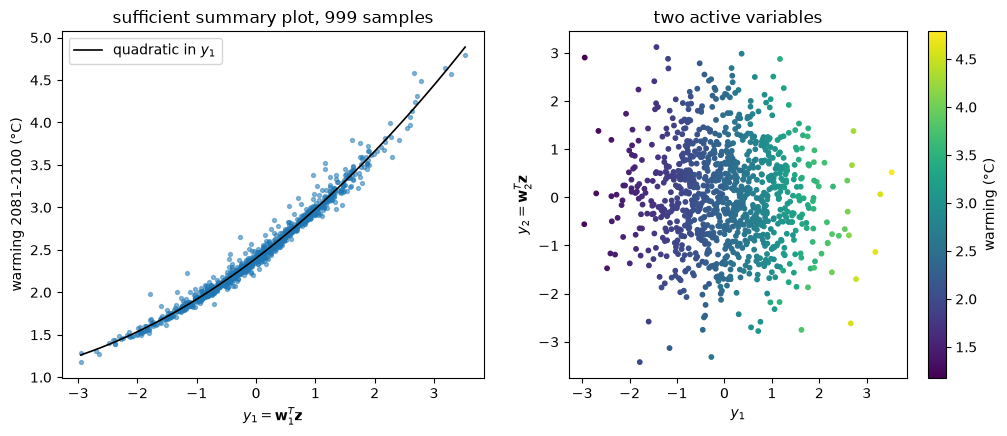

In [8]:
REF = np.eye(6)[:, [2, 4]]  # sign rule: ECS component of w1 positive, NPP0 component of w2 positive
sub1 = ac.orient(ac.active_subspace(space=space, X=Zg, grads=Gw, estimator='as', n=1), by='reference', reference=REF, columns=1)
sub2 = ac.orient(ac.active_subspace(space=space, X=Zg, grads=Gw, estimator='as', n=2), by='reference', reference=REF, columns=2)
y = Zk @ sub2.W[:, :2]     # all finite samples; the subspace used only the first 400 gradients
sur = {d: ac.fit_surrogate(X=Zk, f=warmk, subspace=sub1, kind='poly', degree=d) for d in (1, 2, 3)}
sur2 = ac.fit_surrogate(X=Zk, f=warmk, subspace=sub2, kind='poly', degree=2)
surfull = ac.fit_surrogate(X=Zk, f=warmk, space=space, subspace=None, kind='poly', degree=2)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].scatter(y[:, 0], warmk, s=8, c='C0', alpha=.5)
yy = np.linspace(y[:, 0].min(), y[:, 0].max(), 200)
axes[0].plot(yy, sur[2].evaluate(yy[:, None]), 'k-', lw=1.2, label='quadratic in $y_1$')
axes[0].set_xlabel(r'$y_1 = \mathbf{w}_1^T\mathbf{z}$'); axes[0].set_ylabel('warming 2081-2100 (°C)')
axes[0].legend(); axes[0].set_title(f'sufficient summary plot, {ok.sum()} samples')
sc = axes[1].scatter(y[:, 0], y[:, 1], c=warmk, s=10, cmap='viridis')
axes[1].set_xlabel(r'$y_1$'); axes[1].set_ylabel(r'$y_2 = \mathbf{w}_2^T\mathbf{z}$')
fig.colorbar(sc, ax=axes[1], label='warming (°C)'); axes[1].set_title('two active variables')
plt.close(fig)
print('LOO R^2, warming: polynomial in y1 of degree 1, 2, 3:',
      ', '.join(f'{sur[d].loo_r_squared:.4f}' for d in (1, 2, 3)),
      f'; quadratic in (y1, y2): {sur2.loo_r_squared:.4f}; quadratic in all 6 z: {surfull.loo_r_squared:.4f}')
r1 = warmk - sur[2].evaluate(y[:, :1])
print(f'residual sd of the quadratic in y1: {r1.std():.3f} degC; corr(residual, y2) = {np.corrcoef(r1, y[:, 1])[0, 1]:+.3f}')
fig

Warming is a smooth, convex, increasing function of $y_1$, from about 1.2 °C to 4.8 °C, with little scatter. The leave-one-out $R^2$ of polynomials in $y_1$ is 0.9664 (linear), 0.9834 (quadratic) and 0.9833 (cubic); the residual standard deviation of the quadratic is 0.070 °C, against the 0.543 °C spread of warming. Adding $y_2$ raises the quadratic's LOO $R^2$ to 0.9911, and a quadratic in all six inputs reaches 0.9953, so one variable captures nearly all of the predictable variation and the second takes a small part of the rest. Part of the convexity comes from the lognormal prior of ECS, which is exponential in its $z$.

**Checks without gradients.** Two estimators that use only the 999 function values, and the two halves of the gradient sample:

In [9]:
fq = ac.active_subspace(space=space, X=Zk, f=warmk, estimator='qphd', n=1)
fo = ac.active_subspace(space=space, X=Zk, f=warmk, estimator='ols', n=1)
half = [ac.active_subspace(space=space, X=Zg[i], grads=Gw[i], estimator='as', n=1) for i in (slice(0, Mg // 2), slice(Mg // 2, Mg))]
print(f'QPHD from the 999 values (no gradients): |w1 . w1_qphd| = {abs(W[:, 0] @ fq.W[:, 0]):.4f}, '
      f'eigenvalue ratio |l1/l2| = {abs(fq.eigenvalues[0] / fq.eigenvalues[1]):.1f}')
print(f'OLS direction from the 999 values: |w1 . w_ols| = {abs(W[:, 0] @ fo.W[:, 0]):.4f}')
print(f'gradient halves (rows 0-{Mg // 2 - 1} vs {Mg // 2}-{Mg - 1}): |w1 . w1| = {abs(half[0].W[:, 0] @ half[1].W[:, 0]):.4f}')
# sensitivity to the finite-difference step: the NPP0 components change by tens of per cent between steps
# (DATA.md, Accuracy), so scale that column of the gradients by 0.7 and 1.3 and recompute
for c in (0.7, 1.3):
    G2 = Gw.copy(); G2[:, 4] *= c
    s2 = ac.active_subspace(space=space, X=Zg, grads=G2, estimator='as', n=1)
    print(f'warming, NPP0 gradient component x {c}: lambda1/lambda2 = {s2.eigenvalues[0] / s2.eigenvalues[1]:.1f}, '
          f'|w1 . w1\'| = {abs(W[:, 0] @ s2.W[:, 0]):.4f}')

QPHD from the 999 values (no gradients): |w1 . w1_qphd| = 0.9999, eigenvalue ratio |l1/l2| = 68.1
OLS direction from the 999 values: |w1 . w_ols| = 0.9998
gradient halves (rows 0-198 vs 199-398): |w1 . w1| = 0.9997
warming, NPP0 gradient component x 0.7: lambda1/lambda2 = 47.0, |w1 . w1'| = 0.9962
warming, NPP0 gradient component x 1.3: lambda1/lambda2 = 28.1, |w1 . w1'| = 0.9964


QPHD and OLS find the same direction ($|\mathbf w_1^T\mathbf w_{1}^{\mathrm{QPHD}}| = 0.9999$, $|\mathbf w_1^T\mathbf w^{\mathrm{OLS}}| = 0.9998$), and the subspaces from the two halves of the gradient rows agree to 0.9997. So the active direction does not depend on the finite-difference step. Its eigenvalue ratio does: Hector's outputs are rough at small scales, and between steps 0.1, 0.25 and 0.5 the gradients' NPP$_0$ components differ by tens of per cent (`DATA.md`, Accuracy). Scaling that column by 0.7 or 1.3 leaves $\mathbf w_1$ in place ($|\mathbf w_1^T\mathbf w_1'| = 0.996$) but moves $\lambda_1/\lambda_2$ to 47.0 or 28.1, so the ratio is about 30–45 rather than exactly 36.8.

### Results: CO$_2$ concentration in 2100

The same analysis for the second stored output (sign rule: $Q_{10}$ positive in $\mathbf w_1$). Its finite-difference gradients are rougher than those of warming (`DATA.md`, Accuracy), so the numbers are less precise.

CO2 w1: alpha -0.120, beta -0.516, ECS +0.234, Keff -0.030, NPP0 -0.545, Q10 +0.606
CO2 w2: alpha -0.188, beta -0.162, ECS +0.147, Keff +0.047, NPP0 +0.814, Q10 +0.502
LOO R^2, CO2 quadratic in 1 and 2 active variables: 0.9317, 0.9746
angle check: |w1(warming) . w1(CO2)| = 0.679
CO2, from the 999 values (no gradients): |w1 . w1_qphd| = 0.9996, |w1 . w_ols| = 0.9986
CO2, NPP0 gradient component x 0.7: lambda1/lambda2 = 12.21, |w1 . w1'| = 0.9844
CO2, NPP0 gradient component x 1.3: lambda1/lambda2 = 7.61, |w1 . w1'| = 0.9870


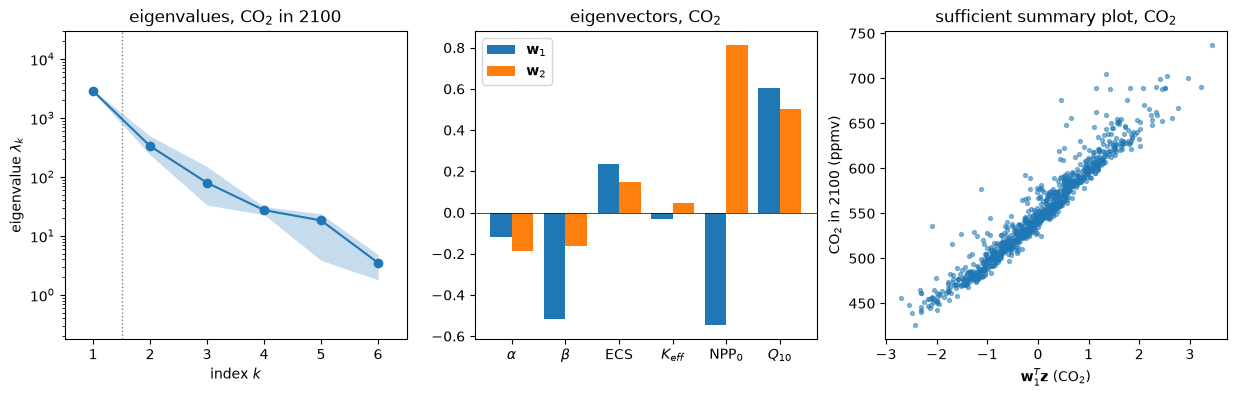

In [10]:
subc = ac.orient(subc, by='reference', reference=np.eye(6)[:, [5]], columns=1)    # Q10 > 0 in w1
Wc = subc.W
lamc = subc.eigenvalues
surc = {d: ac.fit_surrogate(X=Zk, f=co2k, subspace=ac.active_subspace(space=space, X=Zg, grads=Gc, estimator='as', n=d),
                            kind='poly', degree=2) for d in (1, 2)}
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
ac.plotting.plot_eigenvalues(subc, ax=axes[0]); axes[0].set_title('eigenvalues, CO$_2$ in 2100')
for k in range(2):
    axes[1].bar(np.arange(6) + 0.4 * k - 0.2, Wc[:, k], width=0.4, color=f'C{k}', label=rf'$\mathbf{{w}}_{k + 1}$')
axes[1].set_xticks(range(6)); axes[1].set_xticklabels(lab); axes[1].axhline(0, color='k', lw=.5); axes[1].legend()
axes[1].set_title('eigenvectors, CO$_2$')
axes[2].scatter(Zk @ Wc[:, 0], co2k, s=8, alpha=.5)
axes[2].set_xlabel(r'$\mathbf{w}_1^T\mathbf{z}$ (CO$_2$)'); axes[2].set_ylabel('CO$_2$ in 2100 (ppmv)')
axes[2].set_title('sufficient summary plot, CO$_2$')
plt.close(fig)
for k in range(2):
    print(f'CO2 w{k + 1}:', ', '.join(f'{s} {v:+.3f}' for s, v in zip(sym, Wc[:, k])))
print(f'LOO R^2, CO2 quadratic in 1 and 2 active variables: {surc[1].loo_r_squared:.4f}, {surc[2].loo_r_squared:.4f}')
print(f'angle check: |w1(warming) . w1(CO2)| = {abs(W[:, 0] @ Wc[:, 0]):.3f}')
fqc = ac.active_subspace(space=space, X=Zk, f=co2k, estimator='qphd', n=1)
foc = ac.active_subspace(space=space, X=Zk, f=co2k, estimator='ols', n=1)
print(f'CO2, from the 999 values (no gradients): |w1 . w1_qphd| = {abs(Wc[:, 0] @ fqc.W[:, 0]):.4f}, '
      f'|w1 . w_ols| = {abs(Wc[:, 0] @ foc.W[:, 0]):.4f}')
for c in (0.7, 1.3):
    G2 = Gc.copy(); G2[:, 4] *= c
    s2 = ac.active_subspace(space=space, X=Zg, grads=G2, estimator='as', n=1)
    print(f'CO2, NPP0 gradient component x {c}: lambda1/lambda2 = {s2.eigenvalues[0] / s2.eigenvalues[1]:.2f}, '
          f'|w1 . w1\'| = {abs(Wc[:, 0] @ s2.W[:, 0]):.4f}')
fig

For CO$_2$ in 2100 the first ratio is smaller, $\lambda_1/\lambda_2 = 8.57$, with $\lambda_1$ holding 86.1 % of the trace and the first two 96.1 %; the gap rule again picks $n = 1$. The active direction is a carbon-cycle contrast: $Q_{10}$ (+0.606) against NPP$_0$ (−0.545) and $\beta$ (−0.516), with ECS (+0.234) entering through the temperature feedback on respiration; $K_{eff}$ has almost no weight (−0.030). A quadratic in one variable has LOO $R^2$ 0.9317, in two 0.9746, so for CO$_2$ a two-dimensional subspace is the better description. Its first direction makes an angle with that of warming: $|\mathbf w_1^{T}\mathbf w_1^{\mathrm{CO_2}}| = 0.679$. The CO$_2$ gradients are the less accurate ones, but QPHD and OLS from the 999 values alone give the same direction ($|\mathbf w_1^T\mathbf w| = 0.9996$ and 0.9986), and scaling the NPP$_0$ gradient column by 0.7 or 1.3 keeps it ($|\mathbf w_1^T\mathbf w_1'| = 0.984$ and 0.987) while $\lambda_1/\lambda_2$ moves to 12.21 or 7.61.

### Comparison with the paper

The paper's results are weighted probabilities of 2081–2100 warming (Sec. 3, pp. 16–18, Fig. 6B). We recompute Matilda's weights from the stored RMSE (to bootstrap them) and the weighted probability of the paper's ranges with Matilda's `prob_calc` bins $(a, b]$; the intervals come from 2000 bootstrap resamples of the 999 runs, with the weights recomputed in each. We also show the probabilities for two other baselines (see the text below).

max |weights(rmse) - stored weight| = 8.7e-19
mean gmst 1850-1900 over the ensemble: -0.026 degC, sd across runs 0.028
raw Hector gmst (metric_calc in the paper code): weighted P(1.7 < T <= 3.8) = 96.5 %, unweighted 92.6 %
ensemble-mean 1850-1900 baseline: weighted P(1.7 < T <= 3.8) = 97.0 %, unweighted 92.6 %
very likely range, SSP2-4.5 (p. 18)                paper         92 %; weighted  96.9 % (95 % bootstrap 95.7-98.0); prior (unweighted)  92.9 %
IPCC AR6 very likely range, SSP2-4.5 (p. 17)       paper not reported; weighted  67.9 % (95 % bootstrap 64.1-71.4); prior (unweighted)  67.4 %
25-member SSP2-4.5 example, 2.0-4.0 degC (p. 16)   paper        ~90 %; weighted  79.5 % (95 % bootstrap 76.3-82.6); prior (unweighted)  78.9 %
weighted probabilities in the 0.5 degC bins of Fig 6B: (-inf, 1.5] 0.5 %, (1.5, 2.0] 20.0 %, (2.0, 2.5] 48.8 %, (2.5, 3.0] 25.0 %, (3.0, 3.5] 5.6 %, (3.5, 4.0] 0.1 %, (4.0, inf] 0.0 %
weighted 5-50-95 % of warming: 1.75, 2.30, 3.02 degC; unweighted 1.67, 2.40

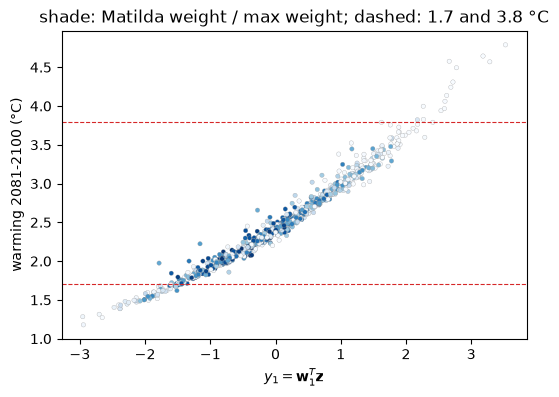

In [11]:
# Matilda's score_bayesian weights (Eqs. 4-6 of the paper, defaults sigma = sd(obs), sensitivity = 1),
# recomputed from the stored rmse to allow a bootstrap
def weights(r):
    L = np.exp(-0.5 * (r / r.std(ddof=1))**2)
    return L / L.sum()
print(f'max |weights(rmse) - stored weight| = {np.max(np.abs(weights(rmsek) - wtsk)):.1e}')

def prob(f, w, a, b):          # Matilda prob_calc bins are (a, b]
    return np.sum(w * ((f > a) & (f <= b)))

rng = np.random.default_rng(SEED)
boot = rng.integers(0, len(warmk), (2000, len(warmk)))
rows = [('very likely range, SSP2-4.5 (p. 18)', 1.7, 3.8, '92 %'),
        ('IPCC AR6 very likely range, SSP2-4.5 (p. 17)', 2.1, 3.5, 'not reported'),
        ('25-member SSP2-4.5 example, 2.0-4.0 degC (p. 16)', 2.0, 4.0, '~90 %')]
metrics = [('per-run 1850-1900 baseline (this data set)', warmk),
           ('raw Hector gmst (metric_calc in the paper code)', warmk + grefk),
           ('ensemble-mean 1850-1900 baseline', warmk + grefk - grefk.mean())]
print(f'mean gmst 1850-1900 over the ensemble: {grefk.mean():.3f} degC, sd across runs {grefk.std(ddof=1):.3f}')
for mname, mval in metrics[1:]:
    print(f'{mname}: weighted P(1.7 < T <= 3.8) = {100 * prob(mval, wtsk, 1.7, 3.8):.1f} %, '
          f'unweighted {100 * np.mean((mval > 1.7) & (mval <= 3.8)):.1f} %')
for label, a, b, paper in rows:
    pw = prob(warmk, wtsk, a, b)
    pu = np.mean((warmk > a) & (warmk <= b))
    bw = np.array([prob(warmk[i], weights(rmsek[i]), a, b) for i in boot])
    lo_, hi_ = np.percentile(bw, [2.5, 97.5])
    print(f'{label:50s} paper {paper:>12s}; weighted {100 * pw:5.1f} % (95 % bootstrap {100 * lo_:.1f}-{100 * hi_:.1f}); '
          f'prior (unweighted) {100 * pu:5.1f} %')
edges = [-np.inf, 1.5, 2.0, 2.5, 3.0, 3.5, 4.0, np.inf]
print('weighted probabilities in the 0.5 degC bins of Fig 6B:',
      ', '.join(f'({a}, {b}] {100 * prob(warmk, wtsk, a, b):.1f} %' for a, b in zip(edges[:-1], edges[1:])))
o = np.argsort(warmk); cw = np.cumsum(wtsk[o])
wq = [warmk[o][np.searchsorted(cw, p)] for p in (0.05, 0.5, 0.95)]
print(f'weighted 5-50-95 % of warming: {wq[0]:.2f}, {wq[1]:.2f}, {wq[2]:.2f} degC; '
      f'unweighted {np.percentile(warmk, 5):.2f}, {np.median(warmk):.2f}, {np.percentile(warmk, 95):.2f}')
print(f'weighted mean ECS {np.sum(wtsk * Xk[:, 2]):.3f} degC (prior sample mean {Xk[:, 2].mean():.3f}); '
      f'weighted mean alpha {np.sum(wtsk * Xk[:, 0]):.3f} (prior {Xk[:, 0].mean():.3f})')
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(Zk @ W[:, 0], warmk, c=wtsk / wtsk.max(), s=10, cmap='Blues', edgecolors='0.6', linewidths=.2)
ax.axhline(1.7, color='C3', lw=.8, ls='--'); ax.axhline(3.8, color='C3', lw=.8, ls='--')
ax.set_xlabel(r'$y_1 = \mathbf{w}_1^T\mathbf{z}$'); ax.set_ylabel('warming 2081-2100 (°C)')
ax.set_title('shade: Matilda weight / max weight; dashed: 1.7 and 3.8 °C')
plt.close(fig)
fig

The stored weights are reproduced from the RMSE to rounding level ($10^{-19}$). With them, warming under SSP2-4.5 falls in the paper's very likely range, 1.7–3.8 °C, with weighted probability 96.9 % (bootstrap 95.7–98.0 %), against the paper's 92 % (p. 18); the unweighted prior fraction is 92.9 %. Our weighted distribution is narrower than the paper's range suggests: weighted 5–50–95 % points 1.75, 2.30 and 3.02 °C, against 1.67, 2.40 and 3.40 °C unweighted; the weights pull ECS down (weighted mean 2.865 °C against 3.005 °C in the sample). For the 25-member example's 2.0–4.0 °C range (~90 %, p. 16) we get 79.5 % (bootstrap 76.3–82.6 %); that example used 25 runs, so a large difference is expected.

**How the paper's code differs.** The paper's analysis scripts (github.com/JGCRI/Brown-etal_2024-PLOSClimate, `02_construct_figures/Fig_06B_plot_probability_bar.R`) normalise GMST by one ensemble-wide 1850–1900 mean, but then compute the metric with `metric_calc`, which reads the raw `value` column, so the published probabilities use the raw Hector GMST (relative to Hector's 1745 start). Here the ensemble's mean 1850–1900 GMST is −0.026 °C, with a spread of 0.028 °C across runs, so the baseline changes little: the weighted probability of 1.7–3.8 °C is 96.5 % for the raw metric and 97.0 % for the ensemble-mean baseline. The paper's scripts also score all four scenarios' runs together and use their own draws (`set.seed(245)`). `check_accuracy.py --paper` reruns those 1000 draws under SSP2-4.5 and finds a weighted 95.2–96.2 % (unweighted 92.2–93.1 %) for the three baselines (`DATA.md`, Accuracy). So the difference from the paper's 92 % is not the sample or the baseline; the paper's value is close to our unweighted fraction. The next cells show a likely cause.

**A likely cause of the 92 %: weights attached to the wrong runs.** In the paper's scripts the 1000 parameter sets are run under four scenarios, and `score_runs` scores the four stacked series of each set together (`01_running_matilda/02_running_matilda_case_study.R`). With the paper's draws, sets 114 and 930 (NPP$_0$ ≈ 14 Pg C yr$^{-1}$) fail under SSP3-7.0 although they run under the other three scenarios, so their weight is NA (`check_accuracy.py --paper`, part 4). `Fig_06B_plot_probability_bar.R` then calls `na.omit()`, which drops these two sets in every scenario, and Matilda v1.0.0's `metric_calc` renumbers the remaining runs `1:nrow(df)` (`R/metric_calc.R`). The following `merge(..., use_weights, by = "run_number")` therefore gives every run from 115 on the weight of a neighbouring, independent run. A weight that is unrelated to the run it multiplies has little effect on a probability, so the result should be close to the unweighted one. We emulate this on our 999 finite runs (numbered 1 to 999, runs 114 and 930 removed, raw-GMST metric as in `metric_calc`) and compare the bins of Fig. 6B with the paper's SSP2-4.5 bar, read from the figure (p. 19; reading error about ±0.01). This is a reconstruction from the authors' code, not a confirmed account of their run.

In [12]:
# Emulation of Fig_06B_plot_probability_bar.R (Brown et al. analysis scripts, commit c9a9b49) with matilda v1.0.0's
# metric_calc: na.omit() drops the runs whose weight is NA, metric_calc renumbers the rest 1..n, and
# merge(metrics, weights, by = "run_number") then pairs metric k with the weight of original run k.
def misaligned(m, w, fail):
    runs = np.arange(1, len(m) + 1)
    keep = ~np.isin(runs, fail)
    mk, new = m[keep], np.arange(1, keep.sum() + 1)
    wt = dict(zip(runs[keep], w[keep]))
    has = np.array([r in wt for r in new])
    return mk[has], np.array([wt[r] for r in new[has]])

raw = warmk + grefk                                       # metric_calc's metric: raw Hector gmst 2081-2100 mean
mm, ww = misaligned(raw, wtsk, (114, 930))
ww = ww / ww.sum()
edges6 = [1.0, 1.5, 2.0, 2.5, 3.0, 3.5, 4.0, 4.5]
fig6b = [0.02, 0.185, 0.39, 0.275, 0.095, 0.03, 0.005]     # paper Fig. 6B, SSP2-4.5, read from the figure (p. 19)
cases = [('correct weights', raw, wtsk), ('no weights', raw, np.full(len(raw), 1 / len(raw))),
         ('misaligned weights', mm, ww)]
print(f"{'':20s} P(1.7<T<=3.8)  " + ' '.join(f'({a:g},{b:g}]' for a, b in zip(edges6[:-1], edges6[1:])) + '   max |bin - Fig. 6B|')
print(f"{'paper (p. 18, Fig. 6B)':20s} {'92 %':>10s}     " + ' '.join(f'{v:9.3f}' for v in fig6b))
for name, m, w in cases:
    b = np.array([prob(m, w, a, c) for a, c in zip(edges6[:-1], edges6[1:])])
    print(f'{name:20s} {100 * prob(m, w, 1.7, 3.8):8.1f} %     ' + ' '.join(f'{v:9.3f}' for v in b)
          + f'   {np.max(np.abs(b - fig6b)):.3f}')
print(f'effective sample size of the weights: correct {1 / np.sum(wtsk**2):.0f}, misaligned {1 / np.sum(ww**2):.0f}')

                     P(1.7<T<=3.8)  (1,1.5] (1.5,2] (2,2.5] (2.5,3] (3,3.5] (3.5,4] (4,4.5]   max |bin - Fig. 6B|
paper (p. 18, Fig. 6B)       92 %         0.020     0.185     0.390     0.275     0.095     0.030     0.005
correct weights          96.5 %         0.007     0.216     0.491     0.243     0.042     0.001     0.000   0.101
no weights               92.6 %         0.022     0.202     0.373     0.259     0.110     0.024     0.005   0.017
misaligned weights       93.2 %         0.028     0.194     0.394     0.261     0.101     0.016     0.003   0.014
effective sample size of the weights: correct 608, misaligned 606


With correct weights the bins put 49 % of the mass in 2.0–2.5 °C and almost none above 3.5 °C, unlike the figure (largest bin difference 0.101). With the misaligned weights the probability of 1.7–3.8 °C falls from 96.5 % to 93.2 % and the bins (0.028, 0.194, 0.394, 0.261, 0.101, 0.016, 0.003) agree with the figure's (≈ 0.02, 0.185, 0.39, 0.275, 0.095, 0.03, 0.005) to 0.014; the unweighted bins agree almost as well (0.017), as expected if the weighting has been scrambled. With the paper's own draws (`check_accuracy.py --paper`, `DATA.md`, Accuracy) the unweighted fraction is 92.2 %, and the same misalignment gives 92.7 % and bins 0.018, 0.185, 0.389, 0.275, 0.100, 0.029, 0.003, within the reading error of the figure. We therefore think the published SSP2-4.5 probabilities (and probably those of the other scenarios) are close to unweighted ones because of this misalignment; the authors have not confirmed it (`DATA.md`, Unknowns).

| quantity | paper (page) | this notebook |
|---|---|---|
| priors of the six parameters | Table 1, p. 5 | the same; sample means/sds printed above |
| P(1.7 < warming ≤ 3.8 °C), SSP2-4.5, weighted | 92 % (p. 18) | 96.9 % (95.7–98.0 %); unweighted 92.9 %; raw metric with the scripts' likely weight misalignment 93.2 % |
| Fig. 6B bins, SSP2-4.5 (0.5 °C, 1.0–4.5 °C) | ≈ 0.02, 0.185, 0.39, 0.275, 0.095, 0.03, 0.005 (read from the figure, p. 19) | correct weights 0.007, 0.216, 0.491, 0.243, 0.042, 0.001, 0.000; misaligned 0.028, 0.194, 0.394, 0.261, 0.101, 0.016, 0.003 |
| P(2.0 < warming ≤ 4.0 °C), SSP2-4.5 | ~90 %, 25 members (p. 16) | 79.5 % (76.3–82.6 %), 999 members |
| P(2.1 < warming ≤ 3.5 °C), IPCC AR6 very likely range | range quoted (p. 17), probability not reported | 67.9 % (64.1–71.4 %) |
| eigenvalues, active subspace, sensitivities | not reported | $\lambda_1/\lambda_2 = 36.8$ (≈ 28–47 with the FD step), $n = 1$, ECS-dominated $\mathbf w_1$ |
| CO$_2$ in 2100 | not reported (CO$_2$ used only for scoring, Fig. 4) | $\lambda_1/\lambda_2 = 8.57$, carbon-cycle direction |

In [13]:
print(f'notebook run time: {time.perf_counter() - t_start:.1f} s')

notebook run time: 2.3 s


### References

1. J. K. Brown, L. Pressburger, A. Snyder, K. Dorheim, S. J. Smith, C. Tebaldi, B. Bond-Lamberty, "Matilda v1.0: An R package for probabilistic climate projections using a reduced complexity climate model", *PLOS Climate* 3(5): e0000295 (2024). [doi:10.1371/journal.pclm.0000295](https://doi.org/10.1371/journal.pclm.0000295). Code: [github.com/JGCRI/matilda](https://github.com/JGCRI/matilda) (tag v1.0.0); analysis scripts: [github.com/JGCRI/Brown-etal_2024-PLOSClimate](https://github.com/JGCRI/Brown-etal_2024-PLOSClimate).
2. K. Dorheim, S. Gering, R. Gieseke, C. Hartin, L. Pressburger, A. N. Shiklomanov, et al., "Hector V3.2.0: functionality and performance of a reduced-complexity climate model", *Geoscientific Model Development* 17(12), 4855–4869 (2024). [doi:10.5194/gmd-17-4855-2024](https://doi.org/10.5194/gmd-17-4855-2024). (The paper cites the discussion version, "Hector V3.1.1", doi:10.5194/egusphere-2023-1477.)
3. C. A. Hartin, P. Patel, A. Schwarber, R. P. Link, B. P. Bond-Lamberty, "A simple object-oriented and open-source model for scientific and policy analyses of the global climate system – Hector v1.0", *Geoscientific Model Development* 8(4), 939–955 (2015). [doi:10.5194/gmd-8-939-2015](https://doi.org/10.5194/gmd-8-939-2015).
4. P. G. Constantine, *Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*, SIAM (2015). [doi:10.1137/1.9781611973860](https://doi.org/10.1137/1.9781611973860).

### Acknowledgments

The paper's research was supported by the U.S. Department of Energy, Office of Science, as part of research in MultiSector Dynamics, Earth and Environmental System Modeling Program; the Pacific Northwest National Laboratory is operated for DOE by Battelle Memorial Institute under contract DE-AC05-76RL01830 [1, p. 2].